In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import timedelta


def filter_patients_with_followup_ecg(df_ecg_all: pd.DataFrame,
                                      patient_col: str,
                                      date_col: str = 'ecg_date',
                                      min_gap_days: int = 365) -> pd.DataFrame:
    """
    Keep patients who have at least one ECG occurring at least `min_gap_days`
    after their first ECG in the cohort (based on `df_first_ecg`).

    Assumes `df_ecg_all` contains columns: `patient_col` and `date_col` (datetime).
    Returns a DataFrame of patient_ids meeting the criterion.
    """
    if date_col not in df_ecg_all.columns:
        raise ValueError(f"Date column '{date_col}' not in df_ecg_all. Available: {list(df_ecg_all.columns)[:10]} ...")
    if patient_col not in df_ecg_all.columns:
        raise ValueError(f"Patient column '{patient_col}' not in df_ecg_all.")

    # Ensure datetime
    ecg_all = df_ecg_all[[patient_col, date_col]].copy()
    ecg_all[date_col] = pd.to_datetime(ecg_all[date_col], errors='coerce')
    ecg_all = ecg_all.dropna(subset=[date_col, patient_col])

    # First ECG date per patient (in the entire ECG table)
    first_dates = ecg_all.groupby(patient_col)[date_col].min().rename('first_ecg_date')
    ecg_all = ecg_all.merge(first_dates, on=patient_col, how='left')

    # Flag follow-up ECGs at least min_gap_days later
    ecg_all['has_followup_12m'] = (ecg_all[date_col] >= ecg_all['first_ecg_date'] + timedelta(days=min_gap_days))

    # Patients who have at least one such follow-up
    eligible_patients = ecg_all.groupby(patient_col)['has_followup_12m'].max()
    eligible_patients = eligible_patients[eligible_patients].index.to_frame(index=False)
    eligible_patients.columns = ['patient_id']
    return eligible_patients


def plot_followup_summary(df_first_ecg: pd.DataFrame,
                          eligible_patients: pd.DataFrame,
                          df_survival: pd.DataFrame = None,
                          save_prefix: str = 'followup_12m'):
    """
    Plot bar summary of inclusion/exclusion and optional KM curves for included cohort.
    """
    os.makedirs(OUTPUT_DIR, exist_ok=True)

    # Counts
    total = df_first_ecg['patient_id'].nunique()
    kept = df_first_ecg[df_first_ecg['patient_id'].isin(eligible_patients['patient_id'])]['patient_id'].nunique()
    excluded = total - kept

    # Bar plot
    plt.figure(figsize=(6,4))
    sns.barplot(x=['Kept (>=12m ECG)', 'Excluded'], y=[kept, excluded], palette=['#2ecc71', '#e74c3c'])
    plt.ylabel('Number of patients')
    plt.title('Patients with/without subsequent ECG ≥ 12 months')
    for i, v in enumerate([kept, excluded]):
        plt.text(i, v + max(1, v*0.01), f"{v:,}", ha='center')
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, f"{save_prefix}_bar.png"), dpi=300, bbox_inches='tight')
    plt.close()

    # If survival provided, regenerate KM on kept cohort
    if df_survival is not None and len(df_survival) > 0:
        kept_surv = df_survival[df_survival['patient_id'].isin(eligible_patients['patient_id'])].copy()
        if len(kept_surv) > 0:
            _ = create_kaplan_meier_curves(kept_surv)
            # Rename outputs to indicate filtered cohort
            for fname in ['kaplan_meier_survival_curves.png', 'kaplan_meier_mace_detailed.png']:
                src = os.path.join(OUTPUT_DIR, fname)
                if os.path.exists(src):
                    dst = os.path.join(OUTPUT_DIR, f"{save_prefix}_" + fname)
                    try:
                        import shutil
                        shutil.move(src, dst)
                    except Exception:
                        pass
        else:
            print('No patients left after filtering for KM plots.')


In [6]:
#!/usr/bin/env python3
"""
5-Year Survival Analysis for New ECG Patients Starting in 2019

This script:
1. Loads ECG parquet data and filters for 2019
2. Identifies new patients (not seen before 2019)
3. Links with hospitalization data for 5-year follow-up
4. Creates Kaplan-Meier survival curves
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta
from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test
import warnings
import os

warnings.filterwarnings('ignore')

# Constants
STUDY_START_YEAR = 2019
FOLLOW_UP_YEARS = 5
FOLLOW_UP_DAYS = FOLLOW_UP_YEARS * 365

# File paths
ECG_PATH = '/media/data1/muse_ge/ECG_ad20241231_cat_labels_v1.3.parquet'
MACE_PATH = '/media/data1/datasets/Hospitalizations_PDF/processed_dataset/merged_df_2017to2023withXA_2024_full_processed.csv'

# Output directory
OUTPUT_DIR = 'survival_analysis_output'

# MACE columns for composite endpoint
MACE_COLUMNS = [
    'mace_cv_death', 'mace_non_fatal_mi', 'mace_non_fatal_stroke',
    'mace_urgent_revascularization', 'mace_heart_failure_hosp',
    'mace_life_threatening_arrhythmia', 'mace_cardiogenic_shock'
]


def load_and_filter_ecg_data(year_filter=2019):
    """Load ECG data and filter for specific year."""
    print(f"\nLoading ECG data and filtering for year {year_filter}...")
    
    # Load ECG data
    df_ecg = pd.read_parquet(ECG_PATH)
    print(f"Total ECG records loaded: {len(df_ecg):,}")
    
    # Check available columns
    print("\nAvailable ECG columns:")
    for col in df_ecg.columns[:20]:  # Show first 20 columns
        print(f"  - {col}")
    
    # Find date column
    date_columns = [col for col in df_ecg.columns if 'date' in col.lower() or 'acquisition' in col.lower()]
    print(f"\nDate-related columns found: {date_columns}")
    
    # Use the most appropriate date column
    if 'AcquisitionDate' in df_ecg.columns:
        date_col = 'AcquisitionDate'
    elif 'acquisition_date' in df_ecg.columns:
        date_col = 'acquisition_date'
    elif 'RestingECG_TestDemographics_AcquisitionDate' in df_ecg.columns:
        date_col = 'RestingECG_TestDemographics_AcquisitionDate'
    elif date_columns:
        # Find the actual date column with 'date' in name
        actual_date_cols = [col for col in date_columns if 'date' in col.lower() and 'acquisition' in col.lower()]
        if actual_date_cols:
            date_col = actual_date_cols[0]
        else:
            date_col = date_columns[0]
    else:
        raise ValueError("No date column found in ECG data")
    
    print(f"Using date column: {date_col}")
    
    # Convert to datetime
    df_ecg['ecg_date'] = pd.to_datetime(df_ecg[date_col], errors='coerce')
    df_ecg['ecg_year'] = df_ecg['ecg_date'].dt.year
    
    # Filter for target year
    df_ecg_filtered = df_ecg[df_ecg['ecg_year'] == year_filter].copy()
    print(f"ECG records in {year_filter}: {len(df_ecg_filtered):,}")
    
    return df_ecg, df_ecg_filtered


def identify_new_patients(df_ecg_all, df_ecg_2019):
    """Identify patients who are new in 2019 (not seen before)."""
    print("\nIdentifying new patients in 2019...")
    
    # Find patient ID column
    patient_id_cols = [col for col in df_ecg_all.columns if 'patient' in col.lower() or 'id' in col.lower()]
    print(f"Patient ID columns found: {patient_id_cols}")
    
    # Use the most appropriate patient ID column
    if 'PatientID' in df_ecg_all.columns:
        patient_col = 'PatientID'
    elif 'patient_id' in df_ecg_all.columns:
        patient_col = 'patient_id'
    elif patient_id_cols:
        patient_col = patient_id_cols[0]
    else:
        raise ValueError("No patient ID column found")
    
    print(f"Using patient ID column: {patient_col}")
    
    # Get patients seen before 2019
    pre_2019 = df_ecg_all[df_ecg_all['ecg_year'] < 2019]
    patients_pre_2019 = set(pre_2019[patient_col].unique())
    print(f"Unique patients before 2019: {len(patients_pre_2019):,}")
    
    # Get patients in 2019
    patients_2019 = set(df_ecg_2019[patient_col].unique())
    print(f"Unique patients in 2019: {len(patients_2019):,}")
    
    # Find new patients
    new_patients = patients_2019 - patients_pre_2019
    print(f"NEW patients in 2019: {len(new_patients):,}")
    
    # Filter for new patients only
    df_new_patients = df_ecg_2019[df_ecg_2019[patient_col].isin(new_patients)].copy()
    df_new_patients['patient_id'] = df_new_patients[patient_col]
    
    return df_new_patients, patient_col


def get_first_ecg_per_patient(df_new_patients):
    """Get the first ECG for each new patient."""
    print("\nGetting first ECG per patient...")
    
    # Sort by patient and date
    df_sorted = df_new_patients.sort_values(['patient_id', 'ecg_date'])
    
    # Get first ECG per patient
    df_first_ecg = df_sorted.groupby('patient_id').first().reset_index()
    
    print(f"Total new patients with first ECG: {len(df_first_ecg):,}")
    
    return df_first_ecg


def link_with_hospitalizations(df_first_ecg, df_mace):
    """Link ECG data with hospitalization/MACE data."""
    print("\nLinking with hospitalization data...")
    
    # Load MACE data if not already loaded
    if isinstance(df_mace, str):
        df_mace = pd.read_csv(df_mace)
    
    print(f"Total hospitalization records: {len(df_mace):,}")
    
    # Convert admission date
    if 'admission_date' in df_mace.columns:
        df_mace['admission_date'] = pd.to_datetime(df_mace['admission_date'], errors='coerce')
    
    # Find patient ID column in MACE data
    mace_patient_cols = [col for col in df_mace.columns if 'patient' in col.lower() or 'medical_record' in col.lower() or 'dossier' in col.lower()]
    print(f"Patient ID columns in MACE data: {mace_patient_cols}")
    
    # Prepare for merge
    if 'medical_record_number' in df_mace.columns:
        df_mace['patient_id_mace'] = df_mace['medical_record_number']
    elif 'Dossier' in df_mace.columns:
        df_mace['patient_id_mace'] = df_mace['Dossier']
    else:
        df_mace['patient_id_mace'] = df_mace[mace_patient_cols[0]] if mace_patient_cols else None
    
    # Create survival data
    survival_data = []
    
    for _, patient in df_first_ecg.iterrows():
        patient_id = patient['patient_id']
        ecg_date = patient['ecg_date']
        
        # Find hospitalizations for this patient
        patient_hosp = df_mace[df_mace['patient_id_mace'] == patient_id].copy()
        
        if len(patient_hosp) > 0 and 'admission_date' in patient_hosp.columns:
            # Calculate days from ECG to admission
            patient_hosp['days_from_ecg'] = (patient_hosp['admission_date'] - ecg_date).dt.days
            
            # Filter for events within follow-up period
            patient_hosp_followup = patient_hosp[
                (patient_hosp['days_from_ecg'] >= 0) & 
                (patient_hosp['days_from_ecg'] <= FOLLOW_UP_DAYS)
            ]
            
            # Check for MACE events
            mace_cols_present = [col for col in MACE_COLUMNS if col in patient_hosp_followup.columns]
            
            if len(patient_hosp_followup) > 0 and mace_cols_present:
                # Check for any MACE event
                patient_hosp_followup['any_mace'] = patient_hosp_followup[mace_cols_present].max(axis=1)
                
                # Find first MACE event
                mace_events = patient_hosp_followup[patient_hosp_followup['any_mace'] > 0]
                
                if len(mace_events) > 0:
                    # Patient had MACE - event occurred
                    first_mace = mace_events.iloc[0]
                    time_to_event = first_mace['days_from_ecg']
                    event_occurred = 1
                    
                    # Check if it was CV death
                    is_cv_death = first_mace.get('mace_cv_death', 0) if 'mace_cv_death' in first_mace else 0
                else:
                    # No MACE during follow-up - censored
                    time_to_event = FOLLOW_UP_DAYS
                    event_occurred = 0
                    is_cv_death = 0
            else:
                # No hospitalizations during follow-up - censored
                time_to_event = FOLLOW_UP_DAYS
                event_occurred = 0
                is_cv_death = 0
        else:
            # No hospitalizations found - censored
            time_to_event = FOLLOW_UP_DAYS
            event_occurred = 0
            is_cv_death = 0
        
        survival_data.append({
            'patient_id': patient_id,
            'ecg_date': ecg_date,
            'time_to_event_days': time_to_event,
            'time_to_event_years': time_to_event / 365.25,
            'event_occurred': event_occurred,
            'is_cv_death': is_cv_death
        })
    
    df_survival = pd.DataFrame(survival_data)
    
    print(f"\nSurvival data summary:")
    print(f"  Total patients: {len(df_survival):,}")
    
    if len(df_survival) > 0:
        print(f"  Patients with MACE: {df_survival['event_occurred'].sum():,} ({df_survival['event_occurred'].mean()*100:.1f}%)")
        print(f"  Patients with CV death: {df_survival['is_cv_death'].sum():,} ({df_survival['is_cv_death'].mean()*100:.1f}%)")
    else:
        print("  No patients found for analysis")
    
    return df_survival


def create_kaplan_meier_curves(df_survival):
    """Create Kaplan-Meier survival curves."""
    print("\nCreating Kaplan-Meier curves...")
    
    os.makedirs(OUTPUT_DIR, exist_ok=True)
    
    # Initialize KM fitter
    kmf = KaplanMeierFitter()
    
    # Create figure with subplots
    fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(16, 12))
    
    # 1. Overall MACE-free survival
    kmf.fit(df_survival['time_to_event_years'], 
            event_observed=df_survival['event_occurred'],
            label='MACE-free survival')
    kmf.plot_survival_function(ax=ax1, ci_show=True)
    ax1.set_xlabel('Time (years)')
    ax1.set_ylabel('MACE-free Survival Probability')
    ax1.set_title('5-Year MACE-free Survival\n(New ECG Patients from 2019)')
    ax1.set_xlim(0, 5)
    ax1.grid(True, alpha=0.3)
    
    # Add statistics
    median_survival = kmf.median_survival_time_
    survival_1yr = kmf.survival_function_at_times(1).values[0]
    survival_3yr = kmf.survival_function_at_times(3).values[0]
    survival_5yr = kmf.survival_function_at_times(5).values[0]
    
    stats_text = f'1-year: {survival_1yr:.1%}\n3-year: {survival_3yr:.1%}\n5-year: {survival_5yr:.1%}'
    ax1.text(0.7, 0.2, stats_text, transform=ax1.transAxes, 
             bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
    
    # 2. CV Death-free survival
    kmf_death = KaplanMeierFitter()
    kmf_death.fit(df_survival['time_to_event_years'], 
                  event_observed=df_survival['is_cv_death'],
                  label='CV death-free survival')
    kmf_death.plot_survival_function(ax=ax2, ci_show=True, color='red')
    ax2.set_xlabel('Time (years)')
    ax2.set_ylabel('CV Death-free Survival Probability')
    ax2.set_title('5-Year Cardiovascular Death-free Survival')
    ax2.set_xlim(0, 5)
    ax2.grid(True, alpha=0.3)
    
    # 3. Event timeline
    events = df_survival[df_survival['event_occurred'] == 1].copy()
    if len(events) > 0:
        ax3.hist(events['time_to_event_years'], bins=20, alpha=0.7, color='darkred', edgecolor='black')
        ax3.set_xlabel('Time to MACE (years)')
        ax3.set_ylabel('Number of Events')
        ax3.set_title('Distribution of Time to First MACE Event')
        ax3.set_xlim(0, 5)
        ax3.grid(True, alpha=0.3)
    
    # 4. Summary statistics table
    summary_data = [
        ['Metric', 'Value'],
        ['Total Patients', f"{len(df_survival):,}"],
        ['MACE Events', f"{df_survival['event_occurred'].sum():,} ({df_survival['event_occurred'].mean()*100:.1f}%)"],
        ['CV Deaths', f"{df_survival['is_cv_death'].sum():,} ({df_survival['is_cv_death'].mean()*100:.1f}%)"],
        ['Median Follow-up (years)', f"{df_survival['time_to_event_years'].median():.1f}"],
        ['1-Year MACE-free Survival', f"{survival_1yr:.1%}"],
        ['3-Year MACE-free Survival', f"{survival_3yr:.1%}"],
        ['5-Year MACE-free Survival', f"{survival_5yr:.1%}"]
    ]
    
    ax4.axis('tight')
    ax4.axis('off')
    table = ax4.table(cellText=summary_data[1:], colLabels=summary_data[0],
                     cellLoc='left', loc='center')
    table.auto_set_font_size(False)
    table.set_fontsize(12)
    table.scale(1.2, 2)
    
    # Style header
    for i in range(2):
        table[(0, i)].set_facecolor('#34495e')
        table[(0, i)].set_text_props(weight='bold', color='white')
    
    plt.suptitle('5-Year Survival Analysis for New ECG Patients (2019 Cohort)', fontsize=16)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, 'kaplan_meier_survival_curves.png'), dpi=300, bbox_inches='tight')
    plt.close()
    
    # Create detailed KM curve for MACE
    plt.figure(figsize=(10, 8))
    kmf.plot_survival_function(ci_show=True)
    plt.xlabel('Time (years)', fontsize=14)
    plt.ylabel('MACE-free Survival Probability', fontsize=14)
    plt.title('Kaplan-Meier Curve: 5-Year MACE-free Survival\nNew ECG Patients from 2019', fontsize=16)
    plt.xlim(0, 5)
    plt.ylim(0, 1)
    plt.grid(True, alpha=0.3)
    
    # Add number at risk
    time_points = [0, 1, 2, 3, 4, 5]
    at_risk = []
    for t in time_points:
        n_at_risk = (df_survival['time_to_event_years'] >= t).sum()
        at_risk.append(n_at_risk)
    
    # Add at-risk table
    for i, (t, n) in enumerate(zip(time_points, at_risk)):
        plt.text(t, -0.1, str(n), ha='center', va='top', transform=plt.gca().get_xaxis_transform())
    
    plt.text(0.5, -0.15, 'Number at risk', ha='center', va='top', transform=plt.gca().transAxes)
    
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, 'kaplan_meier_mace_detailed.png'), dpi=300, bbox_inches='tight')
    plt.close()
    
    print(f"\nKaplan-Meier curves saved to {OUTPUT_DIR}/")
    
    return kmf


def save_results(df_survival, df_first_ecg):
    """Save analysis results to CSV files."""
    os.makedirs(OUTPUT_DIR, exist_ok=True)
    
    # Save survival data
    df_survival.to_csv(os.path.join(OUTPUT_DIR, 'survival_data.csv'), index=False)
    
    # Save patient cohort info
    cohort_summary = {
        'Description': ['New patients in 2019', 'Total follow-up years', 'Patients with MACE', 
                       'Patients with CV death', 'Censored patients'],
        'Count': [
            len(df_survival),
            5,
            df_survival['event_occurred'].sum(),
            df_survival['is_cv_death'].sum(),
            (df_survival['event_occurred'] == 0).sum()
        ],
        'Percentage': [
            '100%',
            'N/A',
            f"{df_survival['event_occurred'].mean()*100:.1f}%",
            f"{df_survival['is_cv_death'].mean()*100:.1f}%",
            f"{(df_survival['event_occurred'] == 0).mean()*100:.1f}%"
        ]
    }
    
    pd.DataFrame(cohort_summary).to_csv(
        os.path.join(OUTPUT_DIR, 'cohort_summary.csv'), 
        index=False
    )
    
    print(f"\nResults saved to {OUTPUT_DIR}/")






if __name__ == "__main__":
    """Main analysis function."""
    print("="*70)
    print("5-YEAR SURVIVAL ANALYSIS FOR NEW ECG PATIENTS")
    print("Starting Year: 2019")
    print("="*70)
    
    try:
        # Load and filter ECG data
        df_ecg_all, df_ecg_2019 = load_and_filter_ecg_data(STUDY_START_YEAR)
        
        # Identify new patients
        df_new_patients, patient_col = identify_new_patients(df_ecg_all, df_ecg_2019)
        
        # Get first ECG per patient
        df_first_ecg = get_first_ecg_per_patient(df_new_patients)

        eligible_patients_12m = filter_patients_with_followup_ecg(
            df_ecg_all=df_ecg_all,
            patient_col=patient_col,
            date_col='ecg_date',
            min_gap_days=365
        )
        print(f"Eligible patients with ≥12-month follow-up ECG: {len(eligible_patients_12m):,}")

        # Restrict the cohort before linking with hospitalizations
        df_first_ecg = df_first_ecg[df_first_ecg['patient_id'].isin(eligible_patients_12m['patient_id'])].copy()
        print(f"Filtered cohort size: {len(df_first_ecg):,}")

        # Bar plot of kept vs excluded (no survival yet)
        plot_followup_summary(
            df_first_ecg=df_first_ecg,
            eligible_patients=eligible_patients_12m,
            df_survival=None,
            save_prefix='followup_12m'
        )
        
        # Load MACE data
        print("\nLoading hospitalization data...")
        df_mace = pd.read_csv(MACE_PATH)
        
        # Link with hospitalizations
        df_survival = link_with_hospitalizations(df_first_ecg, df_mace)
        
        # Create KM curves for filtered cohort
        kmf = create_kaplan_meier_curves(df_survival)

        # Also save filtered-labeled copies of the curves
        plot_followup_summary(
            df_first_ecg=df_first_ecg,
            eligible_patients=eligible_patients_12m,
            df_survival=df_survival,
            save_prefix='followup_12m'
        )
        
        # Save results
        save_results(df_survival, df_first_ecg)
        
        print("\n" + "="*70)
        print("ANALYSIS COMPLETE!")
        print("="*70)
        
    except Exception as e:
        print(f"\nERROR: {str(e)}")
        print("\nPlease check:")
        print("1. File paths are correct")
        print("2. Required columns exist in the data")
        print("3. Date formats are valid")
        raise

5-YEAR SURVIVAL ANALYSIS FOR NEW ECG PATIENTS
Starting Year: 2019

Loading ECG data and filtering for year 2019...
Total ECG records loaded: 1,704,012

Available ECG columns:
  - npy_path
  - RestingECG_MuseInfo_MuseVersion
  - new_PatientID
  - changed_ID
  - RestingECG_PatientDemographics_AgeUnits
  - RestingECG_PatientDemographics_Gender
  - RestingECG_PatientDemographics_PatientLastName
  - RestingECG_PatientDemographics_PatientFirstName
  - RestingECG_TestDemographics_DataType
  - RestingECG_TestDemographics_Site
  - RestingECG_TestDemographics_SiteName
  - RestingECG_TestDemographics_AcquisitionDevice
  - RestingECG_TestDemographics_Status
  - RestingECG_TestDemographics_EditListStatus
  - RestingECG_TestDemographics_Priority
  - RestingECG_TestDemographics_Location
  - RestingECG_TestDemographics_LocationName
  - RestingECG_TestDemographics_AcquisitionTime
  - RestingECG_TestDemographics_AcquisitionDate
  - RestingECG_TestDemographics_CartNumber

Date-related columns found: ['Re

In [2]:
df_first_ecg.head()

,patient_id,npy_path,RestingECG_MuseInfo_MuseVersion,new_PatientID,changed_ID,RestingECG_PatientDemographics_AgeUnits,RestingECG_PatientDemographics_Gender,RestingECG_PatientDemographics_PatientLastName,RestingECG_PatientDemographics_PatientFirstName,RestingECG_TestDemographics_DataType,...,Early repolarization_bert_model,Q wave (posterior - V7-V9)_bert_model,Bi-atrial enlargement_bert_model,LV pacing_bert_model,Brugada_bert_model,Ventricular Rhythm_bert_model,no_qrs_bert_model,RV1 + SV6 > 11 mm,ecg_date,ecg_year
0,54.0,/media/data1/anolin/temp_new_dataset/ecg_npy/0...,9.0.10.18530,54.0,0.0,YEARS,MALE,THIBEAULT,SYLVAIN,RESTING,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2019-11-09,2019
1,64.0,/media/data1/anolin/temp_new_dataset/ecg_npy/0...,9.0.10.18530,64.0,0.0,YEARS,MALE,BIBEAU,FRANCOIS,RESTING,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2019-11-21,2019
2,1567.0,/media/data1/anolin/temp_new_dataset/ecg_npy/0...,9.0.10.18530,1567.0,0.0,YEARS,MALE,FOREST,CLAUDE,RESTING,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2019-02-22,2019
3,1898.0,/media/data1/anolin/temp_new_dataset/ecg_npy/0...,9.0.10.18530,1898.0,0.0,YEARS,MALE,BARON,ANDRE,RESTING,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2019-04-02,2019
4,2636.0,/media/data1/anolin/temp_new_dataset/ecg_npy/0...,9.0.10.18530,2636.0,0.0,YEARS,FEMALE,BARBIERA,ROSALIA,RESTING,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2019-12-17,2019


In [3]:
data = pd.read_parquet("/media/data1/muse_ge/ECG_ad202207_1453937_cat_labels_original_diagnosis_v1.1.parquet")
data.dtypes


index                                         int64
npy_path                                     object
RestingECG_MuseInfo_MuseVersion              object
RestingECG_PatientDemographics_PatientID     object
RestingECG_PatientDemographics_PatientAge    object
                                              ...  
rythme auriculaire gauche                     int64
mauvaise qualité de l'ecg                     int64
bloc de branche droit                         int64
hémibloc antérieur gauche                     int64
dictionary_diagnosis                         object
Length: 583, dtype: object

In [4]:
df_survival["patient_id"] = [int(i) for i in df_survival["patient_id"].values.tolist()]
fam_ecg = df_survival["patient_id"].values.tolist()
fam_ecg = list(map(str,fam_ecg))
#data['RestingECG_PatientDemographics_PatientID'] = [str(i).replace("'","") for i in data['RestingECG_PatientDemographics_PatientID'].tolist()]
data['RestingECG_PatientDemographics_PatientID'] = [str(i).zfill(7) for i in data['RestingECG_PatientDemographics_PatientID'].tolist()]
#data['RestingECG_PatientDemographics_PatientID'] = data['RestingECG_PatientDemographics_PatientID'].str.strip()

fam_ecg = [x.zfill(7) for x in fam_ecg]

# Now try creating the subset
data_ = data.loc[data['RestingECG_PatientDemographics_PatientID'].isin(fam_ecg)]
data_.shape

(45448, 583)

In [5]:
df_survival["patient_id"] = fam_ecg
_ecg = data_['RestingECG_PatientDemographics_PatientID'].values.tolist()
data_["patient_id"] = [x.zfill(7) for x in _ecg]
m_df = pd.merge(df_survival, data_, on="patient_id", how="inner")
print(m_df.shape)
m_df[m_df.columns[:8]].head()

(45448, 589)


,patient_id,ecg_date,time_to_event_days,time_to_event_years,event_occurred,is_cv_death,index,npy_path
0,0000054,2019-11-09,1825,4.996578,0,0,43,/media/data1/anolin/temp_new_dataset/ecg_npy/0...
1,0000054,2019-11-09,1825,4.996578,0,0,44,/media/data1/anolin/temp_new_dataset/ecg_npy/0...
2,0000064,2019-11-21,1825,4.996578,0,0,53,/media/data1/anolin/temp_new_dataset/ecg_npy/0...
3,0001567,2019-02-22,1825,4.996578,0,0,1624,/media/data1/anolin/temp_new_dataset/ecg_npy/0...
4,0001567,2019-02-22,1825,4.996578,0,0,1625,/media/data1/anolin/temp_new_dataset/ecg_npy/0...


In [6]:
m_df["npy_path"].values.tolist()[:5]

['/media/data1/anolin/temp_new_dataset/ecg_npy/0000054_11-09-2019_05-32-56.npy',
 '/media/data1/anolin/temp_new_dataset/ecg_npy/0000054_11-09-2019_05-33-33.npy',
 '/media/data1/anolin/temp_new_dataset/ecg_npy/0000064_11-21-2019_06-51-53.npy',
 '/media/data1/anolin/temp_new_dataset/ecg_npy/0001567_09-17-2020_10-19-27.npy',
 '/media/data1/anolin/temp_new_dataset/ecg_npy/0001567_02-22-2019_09-02-58.npy']

In [6]:
# Convert `ecg_date` to MM-DD-YYYY string format
m_df['ecg_date_str'] = pd.to_datetime(m_df['ecg_date']).dt.strftime('%m-%d-%Y')

# Filter the rows where the date appears in the `npy_path`
df_filtered = m_df[m_df.apply(lambda row: row['ecg_date_str'] in row['npy_path'], axis=1)]

# Optional: Drop the temporary column
df_filtered = df_filtered.drop(columns=['ecg_date_str'])



In [7]:
df_filtered = m_df
print(df_filtered.shape)
df_filtered.head()

(45448, 589)


,patient_id,ecg_date,time_to_event_days,time_to_event_years,event_occurred,is_cv_death,index,npy_path,RestingECG_MuseInfo_MuseVersion,RestingECG_PatientDemographics_PatientID,...,pas d'ondes p décelables,infarctus septal possiblement aigu,inversion de l'onde t en dérivations latérales,rythme auriculaire ectopique,rythme auriculaire entrainé,rythme auriculaire gauche,mauvaise qualité de l'ecg,bloc de branche droit,hémibloc antérieur gauche,dictionary_diagnosis
0,0000054,2019-11-09,1825,4.996578,0,0,43,/media/data1/anolin/temp_new_dataset/ecg_npy/0...,9.0.10.18530,0000054,...,0,0,0,0,0,0,0,0,0,d'âge indéterminéμfibrillation auriculaireμinf...
1,0000054,2019-11-09,1825,4.996578,0,0,44,/media/data1/anolin/temp_new_dataset/ecg_npy/0...,9.0.10.18530,0000054,...,0,0,0,0,0,0,0,0,0,d'âge indéterminéμfibrillation auriculaireμinf...
2,0000064,2019-11-21,1825,4.996578,0,0,53,/media/data1/anolin/temp_new_dataset/ecg_npy/0...,9.0.10.18530,0000064,...,0,0,0,0,0,0,0,0,0,rythme sinusalμecg normal
3,0001567,2019-02-22,1825,4.996578,0,0,1624,/media/data1/anolin/temp_new_dataset/ecg_npy/0...,9.0.10.18530,0001567,...,0,0,0,0,0,0,0,0,0,bradycardie sinusaleμecg normal
4,0001567,2019-02-22,1825,4.996578,0,0,1625,/media/data1/anolin/temp_new_dataset/ecg_npy/0...,9.0.10.18530,0001567,...,0,0,0,0,0,0,0,0,0,rythme sinusalμecg normal


In [8]:
selected_df = df_filtered[list(df_filtered.columns[:8])+["RestingECG_PatientDemographics_PatientAge","RestingECG_PatientDemographics_Gender"]]
for col in df_filtered.columns:
    if "age" in str(col).lower():
        print(col)
    if "gender" in str(col).lower():
        print(col)
    if "l'hypertension" in str(col).lower():
        print(col)

RestingECG_PatientDemographics_PatientAge
RestingECG_PatientDemographics_AgeUnits
RestingECG_PatientDemographics_Gender
RestingECG_ACITIPIAnalysis_TIPIGender
RestingECG_ACITIPIAnalysis_TIPIAgeRange
diagnosis low voltage
original_diagnosis low voltage
Low voltage
sus-décalage du st; possibilité de lésion latérale
sous-décalage du st; possibilité de lésion sous-endocardique
sous-décalage du st; possibilité de lésion sous-endocardique ou imprégnation digitalique
sus-décalage du st; possibilité le lésion antérieure
sus-décalage du st; possibilité de lésion inférieure
sus-décalage du st; possibilité de lésion inférolatérale
sous-décalage du segment st(v3,v4,v5)
bas voltage des qrs
sus-décalage du st; possibilité de lésion antérolatérale
voltage de grande amplitude dans les précordiales moyennes
sus-décalage du st; possibilité de repolarisation précoce, péricardite ou lésion


In [9]:
print(selected_df.shape)
selected_df.head()

(45448, 10)


,patient_id,ecg_date,time_to_event_days,time_to_event_years,event_occurred,is_cv_death,index,npy_path,RestingECG_PatientDemographics_PatientAge,RestingECG_PatientDemographics_Gender
0,0000054,2019-11-09,1825,4.996578,0,0,43,/media/data1/anolin/temp_new_dataset/ecg_npy/0...,54,MALE
1,0000054,2019-11-09,1825,4.996578,0,0,44,/media/data1/anolin/temp_new_dataset/ecg_npy/0...,54,MALE
2,0000064,2019-11-21,1825,4.996578,0,0,53,/media/data1/anolin/temp_new_dataset/ecg_npy/0...,68,MALE
3,0001567,2019-02-22,1825,4.996578,0,0,1624,/media/data1/anolin/temp_new_dataset/ecg_npy/0...,61,MALE
4,0001567,2019-02-22,1825,4.996578,0,0,1625,/media/data1/anolin/temp_new_dataset/ecg_npy/0...,60,MALE


In [9]:
from sklearn.preprocessing import MinMaxScaler
selected_df['gender_mapped'] = selected_df['RestingECG_PatientDemographics_Gender'].map({'MALE': 1, 'FEMALE': 0})
_age = selected_df["RestingECG_PatientDemographics_PatientAge"].values
_age = _age.reshape(-1, 1)

scaler = MinMaxScaler()
_age = scaler.fit_transform(_age)
selected_df['age'] = _age

In [10]:

selected_df.head()

,patient_id,ecg_date,time_to_event_days,time_to_event_years,event_occurred,is_cv_death,index,npy_path,RestingECG_PatientDemographics_PatientAge,RestingECG_PatientDemographics_Gender,gender_mapped,age
0,0000054,2019-11-09,1825,4.996578,0,0,43,/media/data1/anolin/temp_new_dataset/ecg_npy/0...,54,MALE,1,0.516129
1,0000054,2019-11-09,1825,4.996578,0,0,44,/media/data1/anolin/temp_new_dataset/ecg_npy/0...,54,MALE,1,0.516129
2,0000064,2019-11-21,1825,4.996578,0,0,53,/media/data1/anolin/temp_new_dataset/ecg_npy/0...,68,MALE,1,0.666667
3,0001567,2019-02-22,1825,4.996578,0,0,1624,/media/data1/anolin/temp_new_dataset/ecg_npy/0...,61,MALE,1,0.591398
4,0001567,2019-02-22,1825,4.996578,0,0,1625,/media/data1/anolin/temp_new_dataset/ecg_npy/0...,60,MALE,1,0.580645


In [11]:
test_features = selected_df[["age","gender_mapped"]].values
test_labels = selected_df["event_occurred"].values

In [12]:
from sklearn.utils import indexable, _safe_indexing
from sklearn.utils.validation import _num_samples
from sklearn.model_selection._split import _validate_shuffle_split
import torch
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.nn.init as init

# Configuration for different ResNet architectures
resnet_configs = {
    "resnet18": {"block_channels": [64, 64, 128, 256, 512], "num_blocks": [2, 2, 2, 2]},
    "resnet34": {"block_channels": [64, 64, 128, 256, 512], "num_blocks": [3, 4, 6, 3]},
    "resnet50": {"block_channels": [64, 256, 512, 1024, 2048], "num_blocks": [3, 4, 6, 3]},
    "resnet101": {"block_channels": [64, 256, 512, 1024, 2048], "num_blocks": [3, 4, 23, 3]},
    "resnet152": {"block_channels": [64, 256, 512, 1024, 2048], "num_blocks": [3, 8, 36, 3]},
    "resnet200": {"block_channels": [64, 256, 512, 1024, 2048], "num_blocks": [3, 24, 48, 3]},
}

class Mish(nn.Module):
    def forward(self, x):
        return x * torch.tanh(F.softplus(x))

class Swish(nn.Module):
    def forward(self, x):
        return x * torch.sigmoid(x)

class SEBlock(nn.Module):
    def __init__(self, channels, reduction=16):
        super(SEBlock, self).__init__()
        self.global_avg_pool = nn.AdaptiveAvgPool1d(1)  # Squeeze operation
        self.fc1 = nn.Linear(channels, channels // reduction, bias=False)  # Bottleneck
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(channels // reduction, channels, bias=False)
        self.sigmoid = nn.Sigmoid()  # Scale

    def forward(self, x):
        # Input shape: (batch_size, channels, seq_length)
        batch_size, channels, _ = x.size()
        y = self.global_avg_pool(x).view(batch_size, channels)  # (batch_size, channels)
        y = self.fc1(y)
        y = self.relu(y)
        y = self.fc2(y)
        y = self.sigmoid(y).view(batch_size, channels, 1)  # Reshape to (batch_size, channels, 1)
        return x * y  # Channel-wise scaling


class ResNetBlock(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size=3, stride=1, activation="relu", dropout=0.0, use_bias=True, use_attention=False):
        super().__init__()

        self.conv1 = nn.Conv1d(
            in_channels,
            out_channels,
            kernel_size=kernel_size,
            stride=stride,
            padding=kernel_size // 2,
            bias=use_bias,
        )
        self.bn1 = nn.BatchNorm1d(out_channels)

        self.conv2 = nn.Conv1d(
            out_channels,
            out_channels,
            kernel_size=kernel_size,
            stride=1,  # Always keep stride=1 for the second convolution
            padding=kernel_size // 2,
            bias=use_bias,
        )
        self.bn2 = nn.BatchNorm1d(out_channels)

        # Shortcut layer
        self.shortcut = nn.Sequential()
        if in_channels != out_channels or stride > 1:
            self.shortcut = nn.Sequential(
                nn.Conv1d(
                    in_channels,
                    out_channels,
                    kernel_size=1,
                    stride=stride,
                    bias=use_bias,
                ),
                nn.BatchNorm1d(out_channels),
            )

        # Attention mechanism (optional)
        self.use_attention = use_attention
        if use_attention:
            self.attention = SEBlock(out_channels)

        # Activation function
        self.activation = self.get_activation(activation)
        self.dropout = nn.Dropout(p=dropout)

    def get_activation(self, activation):
        if activation == "relu":
            return nn.ReLU()
        elif activation == "mish":
            return Mish()
        elif activation == "swish":
            return Swish()
        else:
            raise ValueError(f"Activation function '{activation}' not supported.")

    def forward(self, x):
        shortcut = self.shortcut(x)

        x = self.conv1(x)
        x = self.bn1(x)
        x = self.activation(x)
        x = self.dropout(x)

        x = self.conv2(x)
        x = self.bn2(x)

        x += shortcut  # Residual addition

        if self.use_attention:
            x = self.attention(x)  # Apply attention

        x = self.activation(x)
        x = self.dropout(x)

        return x


class ResNet1D(nn.Module):
    def __init__(self, input_channels, architecture="resnet18", kernel_sizes=None, strides=None, activation="relu", dropout=0.0, use_bias=True, out_neurons=4, use_attention=False):
        super().__init__()

        config = resnet_configs[architecture]

        if kernel_sizes is None:
            kernel_sizes = [7] * len(config["block_channels"])  # Default kernel size
        if strides is None:
            strides = [2] * len(config["block_channels"])  # Default stride size

        self.conv1 = nn.Conv1d(
            input_channels,
            config["block_channels"][0],
            kernel_size=kernel_sizes[0],
            stride=strides[0],
            padding=kernel_sizes[0] // 2,
            bias=use_bias,
        )
        self.bn1 = nn.BatchNorm1d(config["block_channels"][0])
        self.activation = self.get_activation(activation)
        self.dropout = nn.Dropout(p=dropout)

        self.blocks = nn.Sequential(
            *[
                ResNetBlock(
                    in_channels=config["block_channels"][i],
                    out_channels=config["block_channels"][i + 1],
                    kernel_size=kernel_sizes[i + 1],
                    stride=strides[i + 1],
                    activation=activation,
                    dropout=dropout,
                    use_bias=use_bias,
                    use_attention=use_attention,
                )
                for i in range(len(config["block_channels"]) - 1)
            ]
        )

        self.global_avg_pool = nn.AdaptiveAvgPool1d(1)  # Global average pooling
        self.fc = nn.Linear(config["block_channels"][-1], out_neurons)

    def get_activation(self, activation):
        if activation == "relu":
            return nn.ReLU()
        elif activation == "mish":
            return Mish()
        elif activation == "swish":
            return Swish()
        else:
            raise ValueError(f"Activation function '{activation}' not supported.")

    def forward(self, x):
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.activation(x)
        x = self.dropout(x)

        x = self.blocks(x)

        x = self.global_avg_pool(x)
        x = torch.flatten(x, 1)  # Flatten to (batch_size, channels)
        x = self.fc(x)

        return x
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)
    
class dataset(torch.utils.data.Dataset):

    def __init__(self,ECGs,age ,y):#x_featues
        self.ecgs =torch.from_numpy(ECGs).to(device)
        #self.x_data = torch.from_numpy(x_featues).to(device)
        self.y_data = torch.from_numpy(y).to(device)
        self.age = torch.from_numpy(age)
        #self.len = self.x_data.shape[0]
         
    #dataset length
    def __len__(self):
        self.filelength = len(self.ecgs)
        return self.filelength
    
    #load an one of images
    def __getitem__(self,idx):
        return self.ecgs[idx],self.age[idx], self.y_data[idx]
def load_config(file_path):
    with open(file_path, 'r') as file:
        return yaml.safe_load(file)  

class FullModel(nn.Module):
    def __init__(self, base_model,classes):
        super(FullModel, self).__init__()
        self.base_model = base_model
        self.fc_age = nn.Linear(2, 64)
        self.droup  = nn.Dropout(0.5)
        self.combined_head = nn.Linear(128, classes)

    def forward(self, ecg, age):
        # Get the output from the base model
        #age = age.unsqueeze(1)
        f_model_output = F.relu(self.base_model(ecg))
        age_features = F.relu(self.fc_age(age))
        combined = F.relu(torch.cat((f_model_output, age_features), dim=1))
        combined = self.droup(combined) 
        # Combine it with the age features
        output = self.combined_head(combined)
        return output
from sklearn.metrics import roc_auc_score
def compute_mean_auc(labels_list, outputs_list):
    """
    Compute the AUC for binary classification.

    Args:
        labels_list (list): List of true labels (0 or 1 for binary classification).
        outputs_list (list): List of model outputs (probabilities for class 1).

    Returns:
        float: AUC score.
    """
    labels_array = np.array(labels_list)
    outputs_array = np.array(outputs_list)

    # AUC score for binary classification (just one class, class 1)
    auc_score = roc_auc_score(labels_array, outputs_array)
    
    return auc_score

cuda


In [13]:
from tqdm import tqdm
from sklearn.preprocessing import StandardScaler
import joblib
scaler = StandardScaler()
scaler = joblib.load('/media/data1/mbahani/scaler_ecg.joblib')
def load_and_preprocess_ecg(path):
    with open(path, 'rb') as f:
        ecg = np.load(f)

    # Ensure shape is (12, 2500)
    ecg = np.squeeze(ecg)  # Remove singleton dimensions
    if ecg.shape[0] == 2500 and ecg.shape[1] == 12:
        ecg = ecg.T  # (2500, 12) -> (12, 2500)
    elif ecg.shape != (12, 2500):
        raise ValueError(f"Unexpected ECG shape: {ecg.shape} in file {path}")

    # Repeat time axis -> (12, 5000)
    ecg = np.concatenate([ecg, ecg], axis=1)
    a, b = ecg.shape
    #scaler.fit(ecg.reshape(a * b).reshape(-1, 1))
    ecg = scaler.transform(ecg.reshape(a * b).reshape(-1, 1))
    ecg = np.squeeze(ecg.reshape((a, b)))

    return ecg  # Shape: (12, 5000)

test_ecg_path = selected_df["npy_path"].values.tolist()
test___data = np.empty([len(test_ecg_path), 12, 5000], dtype=np.float32)

for i, path in tqdm(enumerate(test_ecg_path), total=len(test_ecg_path)):
    test___data[i, :, :] = load_and_preprocess_ecg(path)

100%|██████████| 45448/45448 [14:03<00:00, 53.90it/s] 


In [ ]:
def load_and_preprocess_ecg(path):
    with open(path, 'rb') as f:
        ecg = np.load(f)
        ecg = ecg.T
        ecg = ecg[:, :2500]  # Limit to 5000 samples
        c, a, b = ecg.shape
        scaler.fit(ecg.reshape(a * b).reshape(-1, 1))
        ecg = scaler.transform(ecg.reshape(a * b).reshape(-1, 1))
        ecg = np.squeeze(ecg.reshape((a, b)))
    return ecg


100%|██████████| 15175/15175 [00:11<00:00, 1307.63it/s]


In [14]:
np.save("test_ecg_data_norm_scaled_12x5000.npy", test___data)

In [16]:
test___data = np.load("test_ecg_data_norm_scaled_12x5000.npy")
base_model = ResNet1D(
    input_channels=12,
    architecture="resnet152",
    kernel_sizes=[7, 3, 3, 3, 3],  # Custom kernel sizes for each stage
    strides=[2, 2, 2, 2, 2],  # Custom strides for each stage
    activation="relu",
    dropout=0.5,
    out_neurons=64,
    use_attention=True,  # Enable attention
)
model = FullModel(base_model=base_model,classes = 1)
print(f"test___data:  {test___data.shape}, test_features: {test_features.shape} ,  test_labels: {test_labels.shape}")

test_data = dataset(ECGs=test___data,age = test_features, y=test_labels)

#train_loader_undersampling = DataLoader(train_data_undersampled, batch_size=batch_size, shuffle=True, pin_memory=False, num_workers=0, drop_last=True)
valid_loader = torch.utils.data.DataLoader(
test_data, batch_size=32, shuffle=False,
pin_memory=False, num_workers=0)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
checkpoint_path = "/media/data1/mbahani/checkpoint_epoch_binary_v3_age_gender_norm__44__0.7998489444415829.pth"
checkpoint = torch.load(checkpoint_path)
model.load_state_dict(checkpoint['model_state_dict'])
model.to(device)

test___data:  (45448, 12, 5000), test_features: (45448, 2) ,  test_labels: (45448,)


FullModel(
  (base_model): ResNet1D(
    (conv1): Conv1d(12, 64, kernel_size=(7,), stride=(2,), padding=(3,))
    (bn1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (activation): ReLU()
    (dropout): Dropout(p=0.5, inplace=False)
    (blocks): Sequential(
      (0): ResNetBlock(
        (conv1): Conv1d(64, 256, kernel_size=(3,), stride=(2,), padding=(1,))
        (bn1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (conv2): Conv1d(256, 256, kernel_size=(3,), stride=(1,), padding=(1,))
        (bn2): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (shortcut): Sequential(
          (0): Conv1d(64, 256, kernel_size=(1,), stride=(2,))
          (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        )
        (attention): SEBlock(
          (global_avg_pool): AdaptiveAvgPool1d(output_size=1)
          (fc1): Linear(in_features=25

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (roc_curve, auc, precision_recall_curve, average_precision_score, 
                             confusion_matrix, precision_score, recall_score, f1_score)
from sklearn.calibration import calibration_curve
import seaborn as sns

# Set style for professional academic figures
plt.style.use('seaborn-v0_8')
sns.set_style("whitegrid")
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['Times New Roman']
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
plt.rcParams['lines.linewidth'] = 2

def calculate_metrics(y_true, y_scores, threshold=0.5):
    """Calculate all performance metrics"""
    y_pred = (y_scores >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    
    sensitivity = recall_score(y_true, y_pred)
    specificity = tn / (tn + fp)
    ppv = precision_score(y_true, y_pred)
    npv = tn / (tn + fn)
    
    fpr, tpr, thresholds_roc = roc_curve(y_true, y_scores)
    roc_auc = auc(fpr, tpr)
    precision, recall, thresholds_pr = precision_recall_curve(y_true, y_scores)
    auprc = average_precision_score(y_true, y_scores)
    
    prob_true, prob_pred = calibration_curve(y_true, y_scores, n_bins=10)
    
    return {
        'sensitivity': sensitivity,
        'specificity': specificity,
        'ppv': ppv,
        'npv': npv,
        'auc': roc_auc,
        'auprc': auprc,
        'fpr': fpr,
        'tpr': tpr,
        'thresholds_roc': thresholds_roc,
        'precision': precision,
        'recall': recall,
        'prob_true': prob_true,
        'prob_pred': prob_pred
    }

def plot_roc_curve_with_markers(y_true, y_scores, threshold=0.5, save_path=None):
    """Plot ROC curve with sensitivity and specificity markers (original version with point)"""
    metrics = calculate_metrics(y_true, y_scores, threshold)
    fpr, tpr = metrics['fpr'], metrics['tpr']
    
    # Find the point on ROC curve closest to the threshold
    dist = np.abs(metrics['thresholds_roc'] - threshold)
    idx = np.argmin(dist)
    
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.plot(fpr, tpr, color='#1f77b4', lw=2, 
            label=f'ROC curve (AUC = {metrics["auc"]:.2f})')
    ax.plot([0, 1], [0, 1], 'k--', lw=1)
    
    # Mark the operating point (keeping the original point marker)
    ax.plot(fpr[idx], tpr[idx], 'o', markersize=8, 
            label=f'Threshold={threshold:.2f}\n'
                 f'Sens={metrics["sensitivity"]:.2f}\n'
                 f'Spec={metrics["specificity"]:.2f}')
    
    ax.set_xlim([0.0, 1.0])
    ax.set_ylim([0.0, 1.05])
    ax.set_xlabel('1 - Specificity (False Positive Rate)', fontsize=12)
    ax.set_ylabel('Sensitivity (True Positive Rate)', fontsize=12)
    ax.set_title('ROC Curve with Operating Point', fontsize=14)
    ax.legend(loc="lower right")
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()
    
    return fig

def plot_pr_curve_individual(y_true, y_scores, save_path=None):
    """Plot individual Precision-Recall curve"""
    metrics = calculate_metrics(y_true, y_scores)
    
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.plot(metrics['recall'], metrics['precision'], color='#d62728',
            label=f'PR curve (AUPRC = {metrics["auprc"]:.2f})')
    ax.fill_between(metrics['recall'], metrics['precision'], 
                   alpha=0.2, color='#d62728')
    
    ax.set_xlim([0.0, 1.0])
    ax.set_ylim([0.0, 1.05])
    ax.set_xlabel('Recall (Sensitivity)', fontsize=12)
    ax.set_ylabel('Precision (PPV)', fontsize=12)
    ax.set_title('Precision-Recall Curve', fontsize=14)
    ax.legend(loc="upper right")
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()
    
    return fig

def plot_calibration_curve_individual(y_true, y_scores, save_path=None):
    """Plot individual Calibration curve"""
    metrics = calculate_metrics(y_true, y_scores)
    
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.plot(metrics['prob_pred'], metrics['prob_true'], color='#2ca02c', 
            label='Calibration curve')
    ax.plot([0, 1], [0, 1], 'k:', label='Perfect calibration')
    
    ax.set_xlabel('Predicted probability', fontsize=12)
    ax.set_ylabel('True probability', fontsize=12)
    ax.set_title('Calibration Curve', fontsize=14)
    ax.legend(loc="upper left")
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()
    
    return fig

def plot_decision_curve_individual(y_true, y_scores, save_path=None):
    """Plot individual Decision curve (improved version)"""
    thresholds = np.linspace(0, 1, 100)
    net_benefit = []
    prevalence = np.mean(y_true)
    
    for threshold in thresholds:
        y_pred = (y_scores >= threshold).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
        n = len(y_true)
        net_benefit.append((tp / n) - (fp / n) * (threshold / (1 - threshold)))
    
    # Calculate net benefit for treat-all and treat-none strategies
    treat_all = [prevalence - (1 - prevalence) * (t / (1 - t)) for t in thresholds]
    treat_none = [0] * len(thresholds)
    
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.plot(thresholds, net_benefit, color='#9467bd', 
            label='Model decision curve')
    ax.plot(thresholds, treat_all, 'k--', label='Intervention for all')
    ax.plot(thresholds, treat_none, 'k:', label='Intervention for none')
    
    ax.set_xlim([0.0, 1.0])
    ax.set_ylim([-0.05, max(net_benefit) * 1.1])  # Dynamic ylim based on data
    ax.set_xlabel('Threshold Probability', fontsize=12)
    ax.set_ylabel('Net Benefit', fontsize=12)
    ax.set_title('Decision Curve Analysis', fontsize=14)
    ax.legend(loc="upper right")
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()
    
    return fig

In [18]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, confusion_matrix, roc_curve, auc
from sklearn.preprocessing import label_binarize
import seaborn as sns
import torch.nn.functional as F
def compute_mean_auc(labels_list, outputs_list):
    """
    Compute the AUC for binary classification.

    Args:
        labels_list (list): List of true labels (0 or 1 for binary classification).
        outputs_list (list): List of model outputs (probabilities for class 1).

    Returns:
        float: AUC score.
    """
    labels_array = np.array(labels_list)
    outputs_array = np.array(outputs_list)

    # AUC score for binary classification (just one class, class 1)
    auc_score = roc_auc_score(labels_array, outputs_array)
    
    return auc_score
   

def validate_model(model, val_loader):
    model.eval()  # Set the model to evaluation mode
    all_labels = []
    all_outputs = []

    # Disable gradient calculation for validation
    with torch.no_grad():
        for images, age, labels in val_loader:
            images = torch.tensor(images).to(device).float()
            labels = torch.tensor(labels).to(device)
            age = torch.tensor(age).float().to(device)

            outputs = model(images, age)

            # If your model outputs logits, apply sigmoid to get probabilities
            probabilities = torch.sigmoid(outputs).cpu().numpy()  # For binary classification

            all_outputs.extend(probabilities)
            all_labels.extend(labels.cpu().numpy())

    # Compute AUC (binary classification)
    
    auc_score = compute_mean_auc(all_labels, all_outputs)
    


    return auc_score,all_labels,all_outputs





In [33]:
selected_df.head()

,patient_id,ecg_date,time_to_event_days,time_to_event_years,event_occurred,is_cv_death,index,npy_path,RestingECG_PatientDemographics_PatientAge,RestingECG_PatientDemographics_Gender,gender_mapped,age
0,0000054,2019-11-09,1825,4.996578,0,0,43,/media/data1/anolin/temp_new_dataset/ecg_npy/0...,54,MALE,1,0.516129
1,0000054,2019-11-09,1825,4.996578,0,0,44,/media/data1/anolin/temp_new_dataset/ecg_npy/0...,54,MALE,1,0.516129
2,0000064,2019-11-21,1825,4.996578,0,0,53,/media/data1/anolin/temp_new_dataset/ecg_npy/0...,68,MALE,1,0.666667
4,0001567,2019-02-22,1825,4.996578,0,0,1625,/media/data1/anolin/temp_new_dataset/ecg_npy/0...,60,MALE,1,0.580645
5,0001898,2019-04-02,1825,4.996578,0,0,2079,/media/data1/anolin/temp_new_dataset/ecg_npy/0...,93,MALE,1,0.935484


In [20]:
len(selected_df["patient_id"].unique())

13045

0.6380779400714998


findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman
findfont: 

all_labels
0.0    12768
1.0      277
Name: count, dtype: int64
AUC Score: 0.6915008640735413
  entity_id  all_labels   all_outputs
0   0000054         0.0  [0.28043097]
1   0000064         0.0  [0.39397365]
2   0001567         0.0  [0.33177546]
3   0001898         0.0  [0.34032136]
4   0002636         0.0  [0.26388013]
Confusion Matrix:
[[12696    72]
 [  272     5]]


findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman
findfont: 

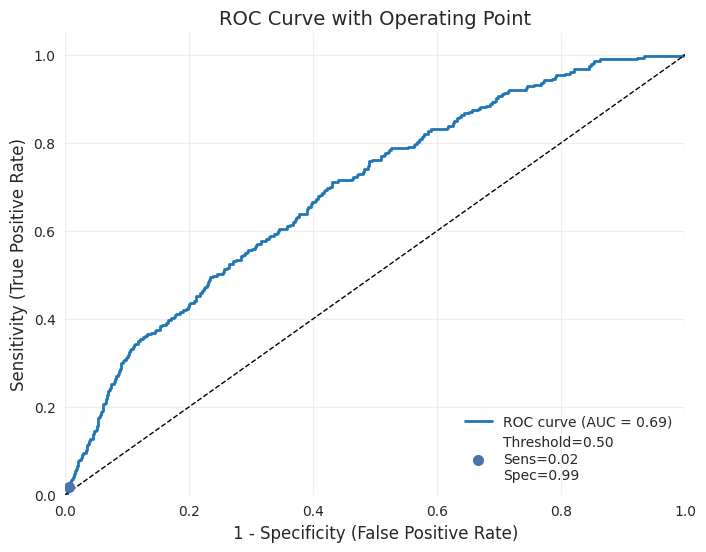

findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman
findfont: 

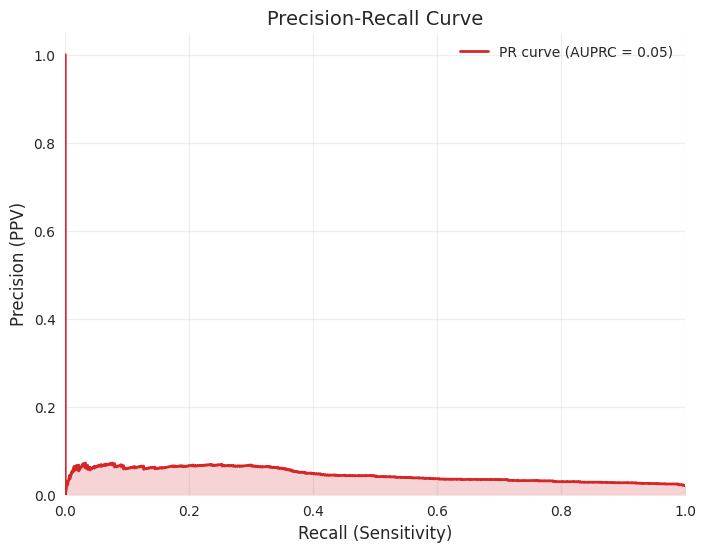

findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman
findfont: 

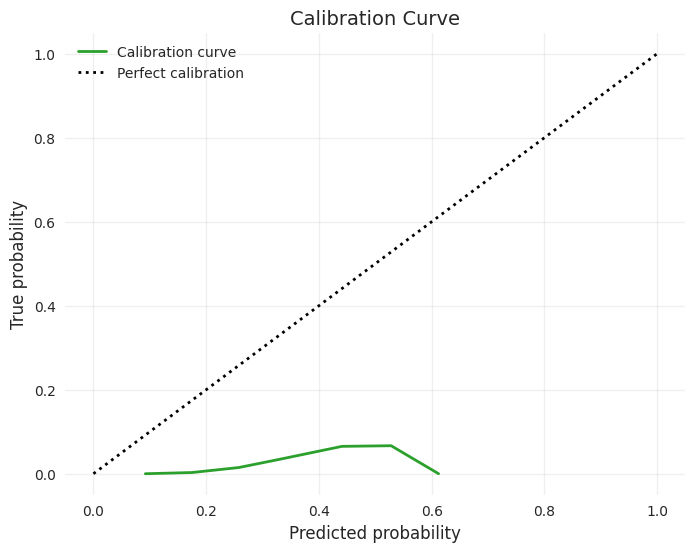

findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman
findfont: 

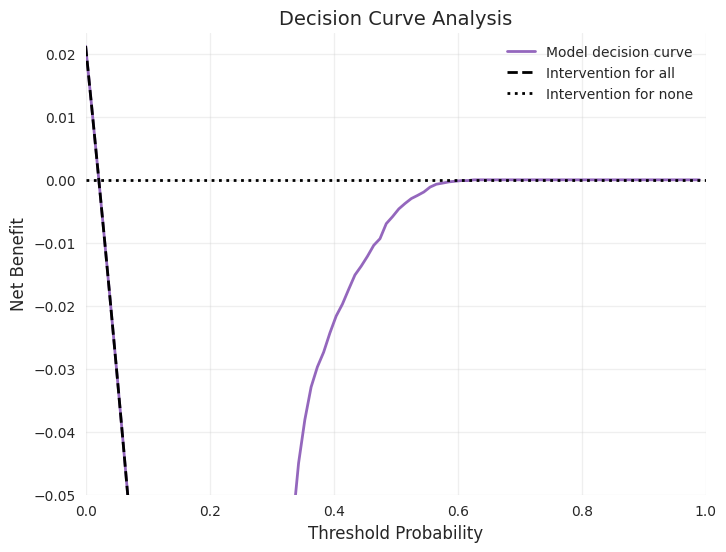


Performance Metrics:
| Metric      |   Value |
|:------------|--------:|
| AUC-ROC     |   0.692 |
| AUPRC       |   0.046 |
| Sensitivity |   0.018 |
| Specificity |   0.994 |
| PPV         |   0.065 |
| NPV         |   0.979 |


In [19]:
auc_score,all_labels,all_outputs = validate_model(model = model, val_loader=valid_loader)
entity_id = selected_df["patient_id"].values.tolist()
print(auc_score)
import pandas as pd
import numpy as np
from sklearn.metrics import roc_auc_score, confusion_matrix, roc_curve, auc
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

# Step 1: Create a DataFrame
data = {
    'entity_id': entity_id,
    'all_labels': list(all_labels),
    'all_outputs': list(all_outputs)
}
df = pd.DataFrame(data)

# Step 2: Group by entity_id and calculate the mean of labels and outputs
grouped_df = df.groupby('entity_id').mean().reset_index()
print(grouped_df['all_labels'].value_counts())
# Step 3: Compute the AUC using the mean values
mean_labels = grouped_df['all_labels']
mean_outputs = grouped_df['all_outputs']
auc_score = roc_auc_score(mean_labels, mean_outputs)

# Output the results
print("AUC Score:", auc_score)
print(grouped_df.head())  # Display the first few rows of the grouped DataFrame

# Step 4: Confusion Matrix
# Convert mean_outputs to binary predictions using a threshold (e.g., 0.5)
binary_predictions = (mean_outputs >= 0.5).astype(int)
conf_matrix = confusion_matrix(mean_labels, binary_predictions)

print("Confusion Matrix:")
print(conf_matrix)

y_true =  np.array(mean_labels, dtype=np.float32)
y_scores = np.array(mean_outputs, dtype=np.float32)

#np.random.seed(42)


# Generate all plots individually
plot_roc_curve_with_markers(y_true, y_scores, threshold=0.5, save_path='roc_curve.png')
plot_pr_curve_individual(y_true, y_scores, save_path='pr_curve.png')
plot_calibration_curve_individual(y_true, y_scores, save_path='calibration_curve.png')
plot_decision_curve_individual(y_true, y_scores, save_path='decision_curve.png')

# Calculate and print metrics
metrics = calculate_metrics(y_true, y_scores)
metrics_df = pd.DataFrame({
    'Metric': ['AUC-ROC', 'AUPRC', 'Sensitivity', 'Specificity', 'PPV', 'NPV'],
    'Value': [f"{metrics['auc']:.3f}", f"{metrics['auprc']:.3f}",
                f"{metrics['sensitivity']:.3f}", f"{metrics['specificity']:.3f}",
                f"{metrics['ppv']:.3f}", f"{metrics['npv']:.3f}"]
})
print("\nPerformance Metrics:")
print(metrics_df.to_markdown(index=False))

In [20]:
#13045
277/(12768+277)

0.021234189344576465

In [ ]:
# Apply follow-up ECG ≥ 12 months filter and plot results

# Determine patient id column used earlier
patient_id_col = 'patient_id'

# Ensure df_ecg_all has the standardized date column 'ecg_date'
# (load_and_filter_ecg_data already created 'ecg_date')

eligible_patients_12m = filter_patients_with_followup_ecg(
    df_ecg_all=df_ecg_all,
    patient_col=patient_col if 'patient_col' in globals() else 'patient_id',
    date_col='ecg_date',
    min_gap_days=365
)

print(f"Eligible patients with ≥12-month follow-up ECG: {len(eligible_patients_12m):,}")

# Plot summary and regenerate KM curves for filtered cohort
plot_followup_summary(
    df_first_ecg=df_first_ecg,
    eligible_patients=eligible_patients_12m,
    df_survival=df_survival,
    save_prefix='followup_12m'
)

# Create a filtered survival dataframe for downstream analyses if needed
df_survival_followup12m = df_survival[df_survival['patient_id'].isin(eligible_patients_12m['patient_id'])].copy()
print(f"Filtered survival cohort size: {len(df_survival_followup12m):,}")

df_survival_followup12m.head()
